# Reto 5 - Lagun Aro: Modelo predictivo de la prima del seguro

Objetivo: estimar el coste esperado del seguro (Prima) a partir de las variables originales del préstamo y del cliente, más la probabilidad de impago estimada por el modelo de impago.

1. Preparación de los datos
2. Las primas censuradas: dos escenarios
3. División en entrenamiento, validación y test
4. Selección de variables
5. Regresión lineal
6. Descenso de gradiente
7. Regresión polinómica
8. Regularización
9. Búsqueda de hiperparámetros
10. Elección del escenario en validación y evaluación final en test
11. Interpretación del modelo final
12. Prima estimada para todos los préstamos
13. Conclusiones

## 1. Preparación de los datos

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import (LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV,
                                  SGDRegressor)
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Código para que no imprima los warnings
import warnings
warnings.filterwarnings("ignore")

In [55]:
datos = pd.read_csv("df_negocio1_valor_presente_con_probabilidad.csv")
print("Filas:", len(datos))
print("Filas repetidas:", datos.duplicated().sum())

datos = datos.drop_duplicates()
print("Filas tras eliminarlas:", len(datos))
datos=datos.drop("Unnamed: 0", axis=1)
datos.head()

Filas: 76513
Filas repetidas: 0
Filas tras eliminarlas: 76513


,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,...,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Divorciado,Estado_Civil_Soltero,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Valor_Presente,Valor_Final,Sistema_frances,Probabilidad_Impago
0,51,56857.0,102886,718,338.0,3,6.18,24.0,0.55,1.0,...,0,0,0,0,1,0,53028.01,56399.58,1,0.031815
1,46,45840.0,30473,689,291.0,1,14.28,36.0,0.34,0.0,...,0,0,0,1,0,0,15236.50,18852.20,0,0.109607
2,36,48156.0,188824,675,161.0,2,13.35,36.0,0.55,0.0,...,0,0,1,0,1,0,103781.93,126651.11,1,0.127424
3,42,41472.0,40000,582,312.0,1,11.83,12.0,0.44,1.0,...,0,1,0,1,0,0,20588.43,21836.64,1,0.111428
4,60,70202.0,40743,652,489.0,2,9.27,48.0,0.25,1.0,...,1,0,0,0,1,0,20371.50,24503.70,0,0.033502


No hay filas repetidas. Las categóricas ya vienen en columnas de 0 y 1.

No usamos:

- Valor_Presente, Valor_Final y Sistema_frances: no son datos originales del préstamo.
- Impago: no se conoce al vender el seguro. En su lugar usamos Probabilidad_Impago.

Quedan 21 columnas candidatas.

In [56]:
candidatas = ["Monto_Inicial", "Duracion", "Scoring_Crediticio", "Ratio_Interes", "Ratio_Deuda_Ingresos", "Ingresos",
              "Probabilidad_Impago", "Edad", "Meses_Empleo", "Num_Creditos", "Posesion_Hipoteca",
              "Personas_Cargo", "Fiador", "Estudios_Escolar", "Estudios_Grado Universitario", "Estudios_Máster",
              "Tipo_Jornada_Laboral_Desempleado", "Tipo_Jornada_Laboral_Jornada completa",
              "Tipo_Jornada_Laboral_Tiempo parcial", "Estado_Civil_Divorciado", "Estado_Civil_Soltero"]
len(candidatas)

21

## 2. Las primas censuradas: dos escenarios

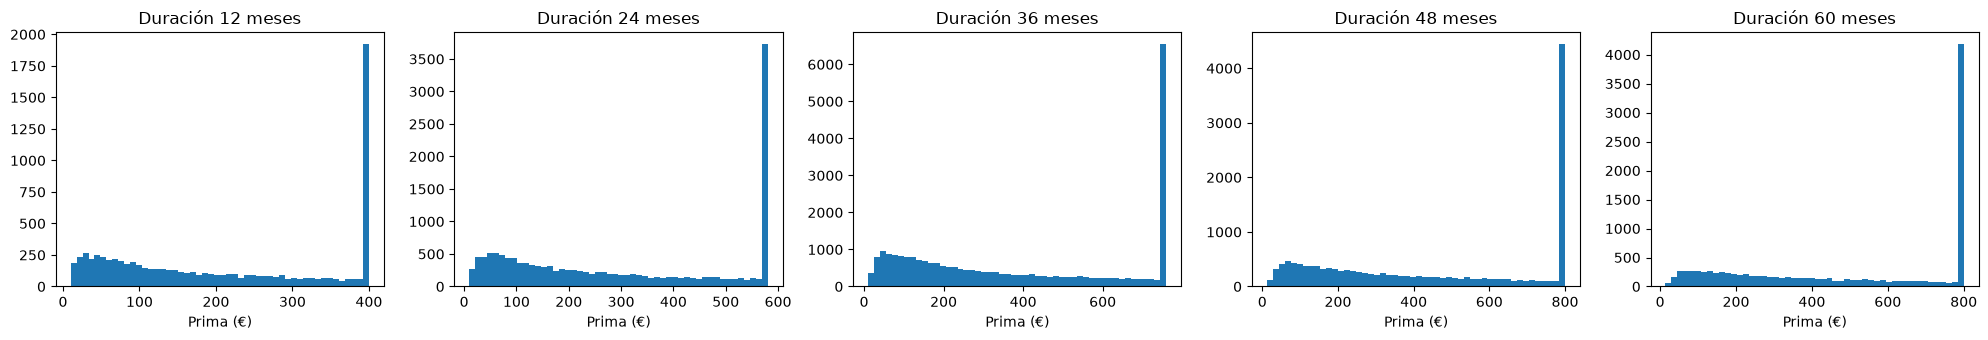

,count,min,max,prestamos_en_el_maximo,%_en_el_maximo
Duracion,,,,,
12.0,7785,10.00,400.0,1879,24.14
24.0,15181,10.00,580.0,3613,23.80
36.0,26915,10.00,760.0,6370,23.67
48.0,15083,11.75,800.0,4319,28.63
60.0,11549,14.03,800.0,4102,35.52


In [57]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, duracion in zip(axes, sorted(datos["Duracion"].unique())):
    ax.hist(datos.loc[datos["Duracion"] == duracion, "Prima"], bins=50)
    ax.set_title(f"Duración {int(duracion)} meses")
    ax.set_xlabel("Prima (€)")
plt.tight_layout()
plt.show()

resumen = datos.groupby("Duracion")["Prima"].agg(["count", "min", "max"])
resumen["prestamos_en_el_maximo"] = datos.groupby("Duracion")["Prima"].apply(lambda s: (s == s.max()).sum())
resumen["%_en_el_maximo"] = resumen["prestamos_en_el_maximo"] / resumen["count"] * 100
resumen.round(2)

Cada duración tiene su prima máxima, y muchos préstamos están justo en ella:

| Duración | Prima máxima | Préstamos en el máximo |
|---|---|---|
| 12 meses | 400 € | 24 % |
| 24 meses | 580 € | 24 % |
| 36 meses | 760 € | 24 % |
| 48 meses | 800 € | 29 % |
| 60 meses | 800 € | 36 % |

Además, la prima nunca baja de 10 €.

Los datos están censurados: esos préstamos siguen en la muestra, pero con la prima recortada al límite, así que no conocemos su prima real. No es lo mismo que datos truncados, en los que esos préstamos habrían desaparecido.

In [58]:
topes = datos.groupby("Duracion")["Prima"].max()
datos["Tope"] = datos["Duracion"].map(topes)
datos["Censurada"] = (datos["Prima"] == datos["Tope"]) | (datos["Prima"] == 10)

print("Topes por duración:", topes.to_dict())
print("Préstamos en el mínimo de 10 €:", (datos["Prima"] == 10).sum())
print("Préstamos censurados:", datos["Censurada"].sum())
print("Porcentaje censurado:", round(datos["Censurada"].mean() * 100, 2), "%")

Topes por duración: {12.0: 400.0, 24.0: 580.0, 36.0: 760.0, 48.0: 800.0, 60.0: 800.0}
Préstamos en el mínimo de 10 €: 50
Préstamos censurados: 20333
Porcentaje censurado: 26.57 %


El 26,6 % de los préstamos (uno de cada cuatro) está censurado. Consecuencias:

1. Recortamos siempre las predicciones entre 10 € y el tope de su duración, porque una regresión no conoce esos límites y puede dar valores imposibles. Todos los errores se calculan con las predicciones recortadas.
2. Probamos dos escenarios y elegimos en el apartado 10:
   - A: todos los datos.
   - B: sin los préstamos censurados.

B puede ayudar porque en los censurados la prima registrada no es la real (es ruido). El riesgo es que no quitamos préstamos al azar, sino siempre los de prima más alta (y más baja): la muestra deja de ser representativa y el modelo solo predice bien dentro del rango que ha visto.

## 3. División en entrenamiento, validación y test

- Entrenamiento (60 %): el modelo aprende.
- Validación (20 %): comparamos modelos, ajustes y escenarios.
- Test (20 %): rendimiento final. No se usa para decidir nada (el resultado sería demasiado optimista); solo en el apartado 10.2.

En B quitamos los censurados de entrenamiento y validación, para que sus ajustes se elijan con datos del mismo tipo. Pero para elegir entre escenarios (10.1) usamos la validación completa: el modelo tendrá que calcular la prima de cualquier préstamo nuevo.

In [59]:
train, test = train_test_split(datos, test_size=0.2, random_state=42)
train, val = train_test_split(train, test_size=0.25, random_state=42)   # 25 % del 80 % restante = 20 % del total

escenarios = {
    "A (todos los datos)": (train, val),
    "B (sin censuradas)": (train[~train["Censurada"]], val[~val["Censurada"]]),
}

for nombre, (tr, va) in escenarios.items():
    print(f"{nombre}: entrenamiento = {len(tr)}, validación = {len(va)}")
print("Validación completa:", len(val))
print("Test:", len(test))

A (todos los datos): entrenamiento = 45907, validación = 15303
B (sin censuradas): entrenamiento = 33765, validación = 11209
Validación completa: 15303
Test: 15303


Métricas:

- RMSE: error típico en euros; pesa más los errores grandes.
- MAE: error medio en euros.
- R²: proporción de la variabilidad de la prima que explica el modelo.

## 4. Selección de variables

Criterios, en los dos escenarios: modelo con todas las variables, significancia, multicolinealidad, Lasso y parsimonia. Como usan modelos lineales, en el apartado 7.2 lo comprobamos con el polinomio.

### 4.1 Regresión lineal con todas las variables

In [60]:
p_valores = {}
for nombre, (tr, va) in escenarios.items():
    print("=" * 30, nombre, "=" * 30)
    modelo = sm.OLS(endog=tr["Prima"], exog=sm.add_constant(tr[candidatas], prepend=True)).fit()
    print(modelo.summary())
    p_valores[nombre] = modelo.pvalues.drop("const")

============================== A (todos los datos) ==============================
                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.679
Method:                 Least Squares   F-statistic:                     4627.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:51:52   Log-Likelihood:            -2.9561e+05
No. Observations:               45907   AIC:                         5.913e+05
Df Residuals:                   45885   BIC:                         5.915e+05
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------

- R²: 0,68 en A y 0,74 en B.
- R² ajustado: casi igual, porque hay muchos datos para pocas variables.
- F-test: p-valor 0 en los dos escenarios; al menos una variable explica la prima.
- P>|t|: p-valor de cada coeficiente (hipótesis nula: el coeficiente vale 0).

### 4.2 Significancia de cada variable

In [61]:
pd.DataFrame(p_valores).round(4)

,A (todos los datos),B (sin censuradas)
Monto_Inicial,0.0000,0.0000
Duracion,0.0000,0.0000
Scoring_Crediticio,0.0000,0.0000
Ratio_Interes,0.0000,0.0000
Ratio_Deuda_Ingresos,0.0000,0.0000
Ingresos,0.0000,0.0604
Probabilidad_Impago,0.0000,0.0000
Edad,0.0000,0.0000
Meses_Empleo,0.8124,0.9207
Num_Creditos,0.8901,0.7275


Con un nivel de significación del 5 %:

- p < 0,05: hay evidencia de que la variable tiene efecto, dadas las demás.
- p > 0,05: no hay evidencia suficiente. No demuestra que el coeficiente valga 0: el efecto puede ser pequeño o estar recogido por otras variables.

| Resultado | Variables |
|---|---|
| Significativas en A y B | Monto_Inicial, Duracion, Scoring_Crediticio, Ratio_Interes, Ratio_Deuda_Ingresos, Probabilidad_Impago, Edad, Estudios_Escolar, Estudios_Grado Universitario, Estado_Civil_Soltero |
| Solo en un escenario | Ingresos (A), Estudios_Máster y Estado_Civil_Divorciado (B) |
| En ninguno | Meses_Empleo, Num_Creditos, Posesion_Hipoteca, Personas_Cargo, Fiador, Tipo_Jornada_Laboral |

Dos avisos:

- Con 46.000 préstamos casi todo sale significativo. Estado_Civil_Soltero lo es, pero su efecto es de unos -4,5 €. Significativo no es lo mismo que importante, así que también miramos cuánto mejora la predicción.
- El coeficiente de Probabilidad_Impago es negativo (-505 en A), como si más riesgo diera menos prima. Lo vemos en 4.3.

### 4.3 Multicolinealidad

La regresión lineal supone que las variables explicativas no están muy correlacionadas: si lo están, dan la misma información y sus coeficientes se vuelven inestables.

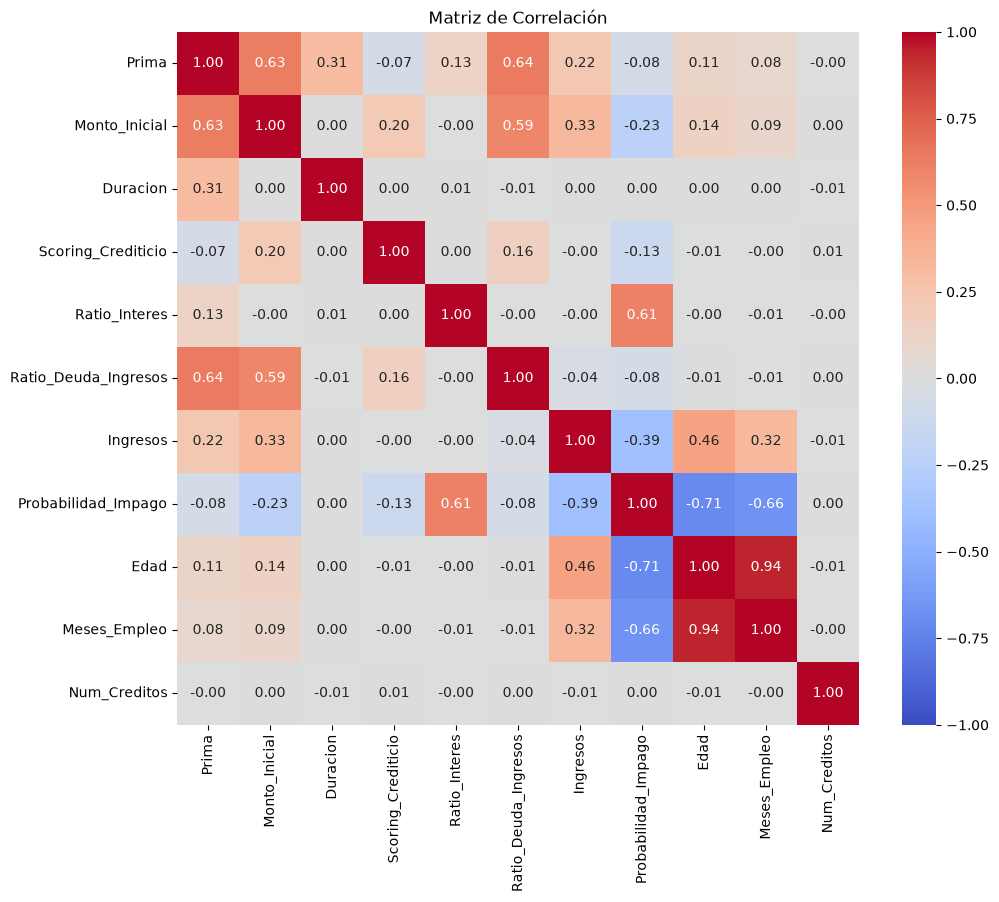

In [62]:
numericas = ["Prima", "Monto_Inicial", "Duracion", "Scoring_Crediticio", "Ratio_Interes", "Ratio_Deuda_Ingresos",
             "Ingresos", "Probabilidad_Impago", "Edad", "Meses_Empleo", "Num_Creditos"]
corr = train[numericas].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de Correlación")
plt.show()

¿Cuánta información de Probabilidad_Impago ya está en las otras 20 columnas?

In [63]:
otras = [c for c in candidatas if c != "Probabilidad_Impago"]
modelo_prob = LinearRegression().fit(train[otras], train["Probabilidad_Impago"])
print("R2:", round(modelo_prob.score(train[otras], train["Probabilidad_Impago"]), 3))

R2: 0.907


- Edad y Meses_Empleo: correlación 0,94, dan casi la misma información.
- Probabilidad_Impago: muy relacionada con Edad (-0,71), Meses_Empleo (-0,66), Ratio_Interes (0,61) e Ingresos (-0,39). Las otras columnas explican el 90,7 % de su variabilidad, porque se calcula a partir de ellas. Por eso su coeficiente negativo no se puede interpretar: el efecto se reparte entre variables que dicen lo mismo.
- Monto_Inicial y Ratio_Deuda_Ingresos: 0,59, moderada. Mantenemos las dos.

### 4.4 Lasso

Lasso penaliza el tamaño de los coeficientes y lleva a 0 los de las variables menos relevantes. Cuanto mayor es alpha, más variables elimina; las que aguantan son las más importantes. Antes hay que estandarizar, para que la penalización trate igual a todas.

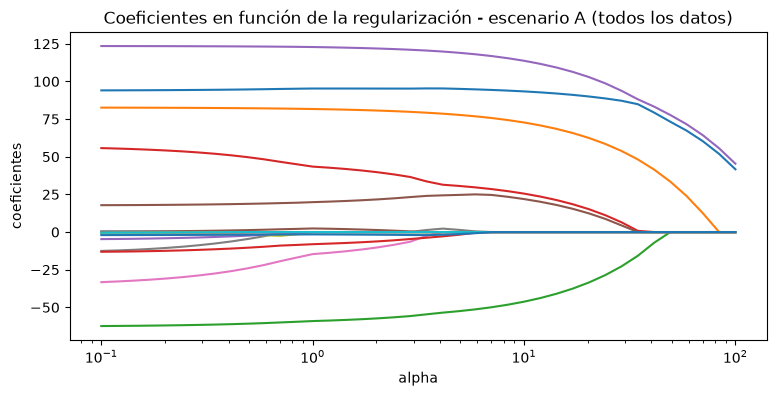

alpha = 1: 11 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Ingresos', 'Probabilidad_Impago', 'Estudios_Escolar', 'Estudios_Grado Universitario', 'Estudios_Máster', 'Estado_Civil_Soltero']
alpha = 3: 10 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Ingresos', 'Probabilidad_Impago', 'Estudios_Escolar', 'Estudios_Máster', 'Estado_Civil_Soltero']
alpha = 10: 6 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Ingresos']
alpha = 20: 6 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Ingresos']
alpha = 30: 6 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Ingresos']
alpha = 60: 3 variables -> ['Monto_Inicial', 'Duracion', 'Ratio_Deuda_Ingresos']


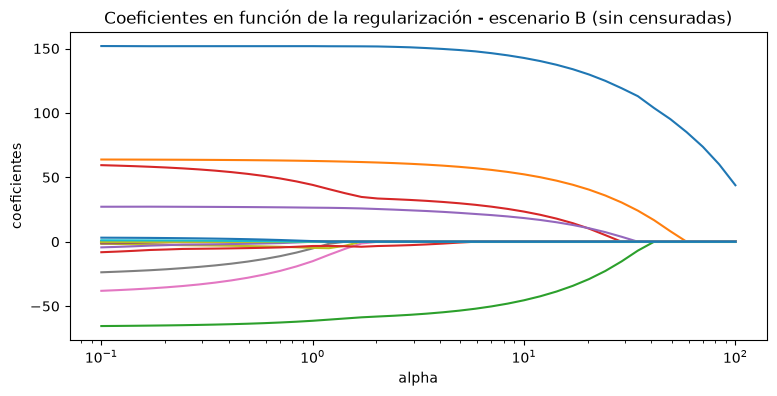

alpha = 1: 11 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Probabilidad_Impago', 'Edad', 'Meses_Empleo', 'Estudios_Escolar', 'Estudios_Máster', 'Estado_Civil_Soltero']
alpha = 3: 6 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos', 'Estudios_Escolar']
alpha = 10: 5 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos']
alpha = 20: 5 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Interes', 'Ratio_Deuda_Ingresos']
alpha = 30: 4 variables -> ['Monto_Inicial', 'Duracion', 'Scoring_Crediticio', 'Ratio_Deuda_Ingresos']
alpha = 60: 1 variables -> ['Monto_Inicial']


In [64]:
for nombre, (tr, va) in escenarios.items():
    X_esc = StandardScaler().fit_transform(tr[candidatas])

    alphas = np.logspace(-1, 2, 40)
    coefs = [Lasso(alpha=a).fit(X_esc, tr["Prima"]).coef_ for a in alphas]

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(alphas, coefs)
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("coeficientes")
    ax.set_title(f"Coeficientes en función de la regularización - escenario {nombre}")
    plt.show()

    for alpha in [1, 3, 10, 20, 30, 60]:
        modelo = Lasso(alpha=alpha).fit(X_esc, tr["Prima"])
        quedan = [c for c, coef in zip(candidatas, modelo.coef_) if coef != 0]
        print(f"alpha = {alpha}: {len(quedan)} variables -> {quedan}")

- A: con alpha entre 10 y 30 quedan siempre las mismas 6 variables: Monto_Inicial, Duracion, Scoring_Crediticio, Ratio_Interes, Ratio_Deuda_Ingresos e Ingresos.
- B: igual, pero los Ingresos salen antes (con alpha = 3 ya no están), coherente con su p-valor de 0,06 en B.
- Probabilidad_Impago desaparece entre alpha = 3 y 10 en A (antes en B): entre variables que dan la misma información, Lasso se queda con unas y elimina las otras.

Probabilidad_Impago, Edad, Estudios y Estado_Civil son significativas, pero Lasso las considera poco relevantes.

### 4.5 Principio de parsimonia

Entre modelos con capacidad predictiva similar, elegimos el más sencillo: se sobreajusta menos y se interpreta mejor. Comparamos conjuntos de variables con el error en validación, con grado 1 y 2.

In [65]:
seis = ["Monto_Inicial", "Duracion", "Scoring_Crediticio", "Ratio_Interes", "Ratio_Deuda_Ingresos", "Ingresos"]
conjuntos = {
    "21 candidatas": candidatas,
    "Significativas": seis + ["Probabilidad_Impago", "Meses_Empleo", "Estudios_Escolar",
                              "Estudios_Grado Universitario", "Estado_Civil_Soltero"],
    "6 de Lasso + Probabilidad_Impago": seis + ["Probabilidad_Impago"],
    "6 de Lasso": seis,
    "3 variables": ["Monto_Inicial", "Duracion", "Ratio_Deuda_Ingresos"],
}

resultados = []
for nombre_esc, (tr, va) in escenarios.items():
    for nombre, variables in conjuntos.items():
        for grado in [1, 2]:
            scaler = StandardScaler()
            poly = PolynomialFeatures(degree=grado, include_bias=False)
            X_tr = poly.fit_transform(scaler.fit_transform(tr[variables]))
            X_va = poly.transform(scaler.transform(va[variables]))
            modelo = LinearRegression().fit(X_tr, tr["Prima"])
            prediccion = np.clip(modelo.predict(X_va), 10, va["Tope"])   # recortamos entre 10 € y el tope
            resultados.append([nombre_esc, nombre, grado, root_mean_squared_error(va["Prima"], prediccion)])

resultados = pd.DataFrame(resultados, columns=["escenario", "conjunto", "grado", "RMSE_validacion"])
resultados.pivot_table(index="conjunto", columns=["escenario", "grado"], values="RMSE_validacion").round(2)

escenario                        A (todos los datos)          \
grado                                              1       2   
conjunto                                                       
21 candidatas                                 141.82   88.75   
3 variables                                   163.16  128.07   
6 de Lasso                                    142.55   90.53   
6 de Lasso + Probabilidad_Impago              142.37   90.03   
Significativas                                141.93   88.87   

escenario                        B (sin censuradas)          
grado                                             1       2  
conjunto                                                     
21 candidatas                                 93.39   66.35  
3 variables                                  116.96  108.94  
6 de Lasso                                    94.37   67.05  
6 de Lasso + Probabilidad_Impago              94.32   66.75  
Significativas                                93.71   66.34

- Las 21 candidatas, las significativas y las 6 de Lasso (con o sin Probabilidad_Impago) dan casi el mismo error: en A, 141,8-142,6 € con la recta y 88,8-90,5 € con grado 2. Igual en B.
- Añadir Probabilidad_Impago mejora 0,5 € como mucho.
- Con 3 variables el error sube mucho (163 € y 128 € en A).

Nos quedamos con las 6 de Lasso en los dos escenarios (así la comparación entre escenarios es justa; en 7.2 se ve que quitar Ingresos también empeora B):

| Variable | Decisión | Motivo |
|---|---|---|
| Monto_Inicial, Duracion, Scoring_Crediticio, Ratio_Interes, Ratio_Deuda_Ingresos, Ingresos | Sí | Significativas, Lasso las mantiene y quitar más empeora el error. |
| Probabilidad_Impago | No | Su información ya está casi toda en las demás (R² = 0,907), Lasso la elimina y no mejora el error. |
| Edad, Estudios, Estado_Civil | No | Efectos pequeños, Lasso las elimina y no mejoran el error. |
| Resto | No | Sin evidencia de efecto y no mejoran el error. |

Que la probabilidad de impago no entre no significa que la prima no dependa del riesgo: Scoring_Crediticio y Ratio_Interes, dos indicadores de riesgo, están entre las elegidas. Lo que no hace es aportar información nueva.

In [66]:
variables = ["Monto_Inicial", "Duracion", "Scoring_Crediticio", "Ratio_Interes", "Ratio_Deuda_Ingresos", "Ingresos"]

## 5. Regresión lineal
### 5.1 Ajuste e interpretación

Mínimos cuadrados: los coeficientes que minimizan la suma de errores al cuadrado, con la ecuación normal:

$$\hat{\beta} = (X^T X)^{-1} X^T y$$

In [67]:
modelos_lineales = {}
for nombre, (tr, va) in escenarios.items():
    print("=" * 30, nombre, "=" * 30)
    modelos_lineales[nombre] = sm.OLS(endog=tr["Prima"], exog=sm.add_constant(tr[variables], prepend=True)).fit()
    print(modelos_lineales[nombre].summary())

============================== A (todos los datos) ==============================
                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.676
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                 1.599e+04
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:52:00   Log-Likelihood:            -2.9581e+05
No. Observations:               45907   AIC:                         5.916e+05
Df Residuals:                   45900   BIC:                         5.917e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------

| | A | B |
|---|---|---|
| R² | 0,676 | 0,738 |
| F-test (p-valor) | 0 | 0 |
| Durbin-Watson | 2,00 | 2,00 |

Las seis variables tienen p-valor 0 y el R² es casi igual que con las 21 (0,679 en A), lo que confirma la parsimonia. El R² de B no es comparable: se mide sin los censurados.

Efecto de cada variable en A, con las demás fijas:

- Monto_Inicial: +2,1 € por cada 1.000 € de préstamo.
- Duracion: +5,8 € por mes.
- Scoring_Crediticio: -67 € por cada 100 puntos.
- Ratio_Interes: +9,4 € por punto de interés.
- Ratio_Deuda_Ingresos: +69 € por cada 0,1.
- Ingresos: +20 € por cada 10.000 €.

En B los signos son iguales, pero el efecto del Monto es 4 veces mayor y el del Ratio_Deuda_Ingresos 4 veces menor: al quitar las primas más altas, el modelo aprende relaciones distintas.

Intervalos de confianza de los coeficientes al 95 %:

In [68]:
intervalos = []
for nombre, modelo in modelos_lineales.items():
    ci = modelo.conf_int(alpha=0.05)
    ci.columns = [f"{nombre} 2.5%", f"{nombre} 97.5%"]
    intervalos.append(ci)
pd.concat(intervalos, axis=1)

,A (todos los datos) 2.5%,A (todos los datos) 97.5%,B (sin censuradas) 2.5%,B (sin censuradas) 97.5%
const,122.804707,149.444678,184.782859,204.945124
Monto_Inicial,0.002027,0.002110,0.008561,0.008738
Duracion,5.720814,5.916611,4.492394,4.648329
Scoring_Crediticio,-0.684130,-0.651624,-0.696931,-0.671250
Ratio_Interes,8.986802,9.718353,9.208361,9.785630
Ratio_Deuda_Ingresos,676.316405,696.333483,159.385609,177.168831
Ingresos,0.001853,0.002047,0.000172,0.000330


Ningún intervalo incluye el 0.

### 5.2 Intervalo de confianza e intervalo de predicción

- Confianza: dónde está la prima media de los préstamos con esas características.
- Predicción: dónde estará la prima de un préstamo concreto. Es más ancho.

Para el primer préstamo de validación:

In [69]:
prestamo = val[variables].iloc[[0]].copy()
prestamo.insert(0, "const", 1.0)   # columna de unos para el intercepto
print("Prima real:", val["Prima"].iloc[0])

for nombre, modelo in modelos_lineales.items():
    print(nombre)
    print(modelo.get_prediction(exog=prestamo).summary_frame(alpha=0.05).round(2))

Prima real: 227.16
A (todos los datos)
         mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
34496  273.24     1.41         270.47          276.0        -24.99   

       obs_ci_upper  
34496        571.46  
B (sin censuradas)
         mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  \
34496  294.26     1.08         292.15         296.38         94.97   

       obs_ci_upper  
34496        493.55  


Prima real: 227 €. En A, la prima media estimada es 273 € (confianza: 270-276 €), pero el intervalo de predicción va de -25 € a 571 €, con valores negativos imposibles. En B va de 95 € a 494 €. Los dos son muy anchos: el modelo lineal deja mucha variabilidad sin explicar y no conoce los límites de la prima.

### 5.3 Diagnóstico de los residuos

Supuestos: residuos normales, con varianza constante (homocedasticidad), independientes, y variables sin multicolinealidad. En A, los censurados van en rojo.

A (todos los datos) - test de normalidad: estadístico = 142.8, p-value = 0.0000
B (sin censuradas) - test de normalidad: estadístico = 2152.4, p-value = 0.0000


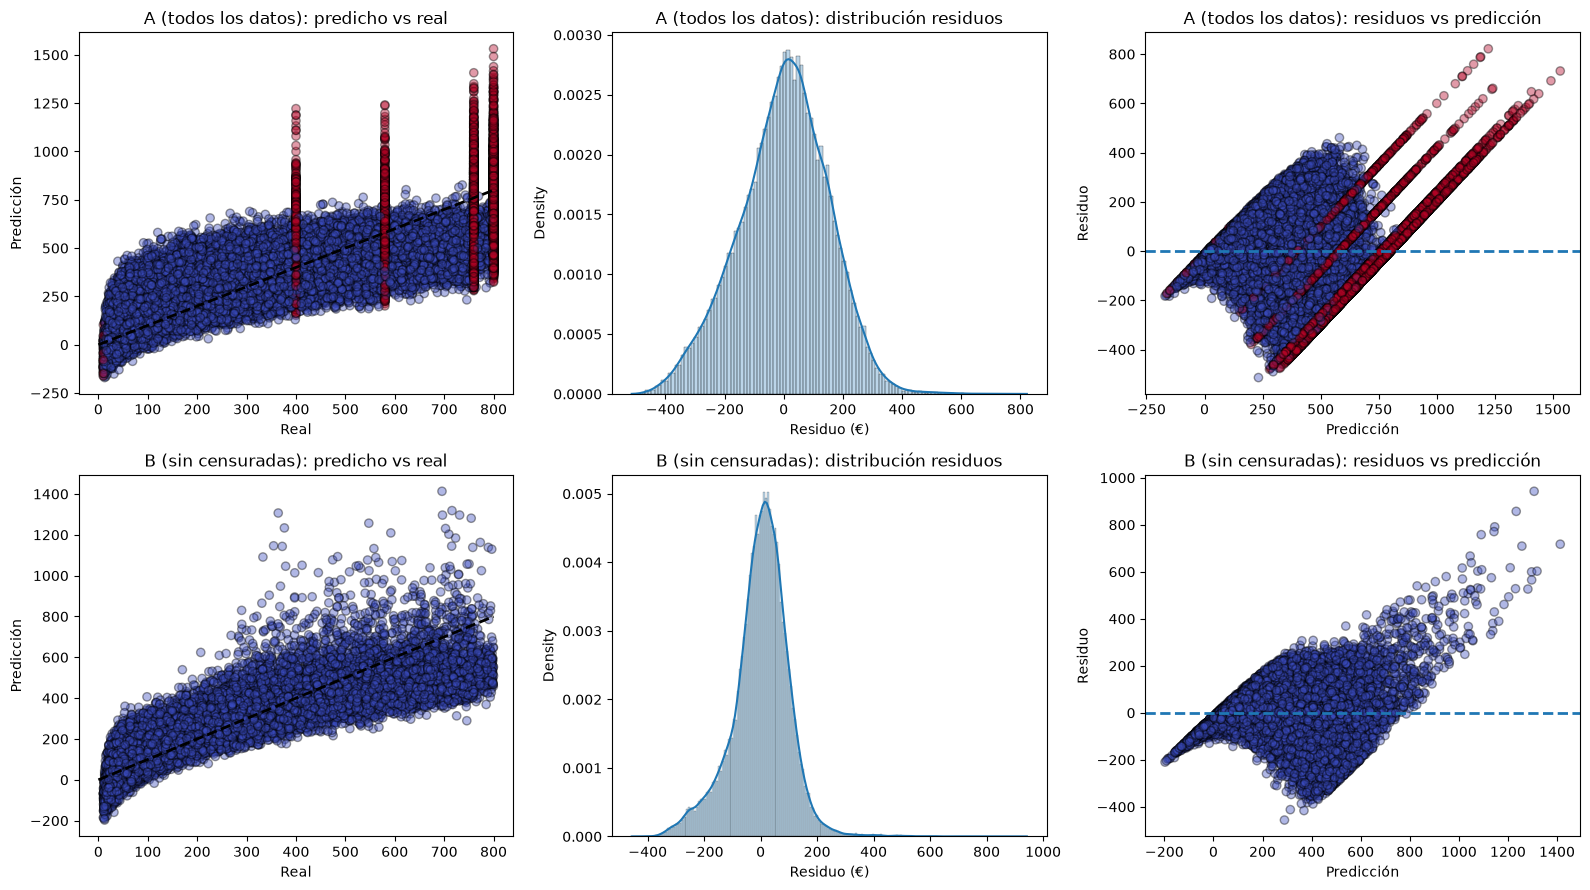

In [70]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))

for fila, (nombre, (tr, va)) in enumerate(escenarios.items()):
    modelo = LinearRegression().fit(tr[variables], tr["Prima"])
    prediccion = modelo.predict(tr[variables])
    residuos = prediccion - tr["Prima"]

    axes[fila, 0].scatter(tr["Prima"], prediccion, c=tr["Censurada"], cmap="coolwarm", edgecolors=(0, 0, 0), alpha=0.4)
    axes[fila, 0].plot([0, 800], [0, 800], "k--", lw=2)
    axes[fila, 0].set_title(f"{nombre}: predicho vs real")
    axes[fila, 0].set_xlabel("Real")
    axes[fila, 0].set_ylabel("Predicción")

    sns.histplot(data=residuos, stat="density", kde=True, alpha=0.3, ax=axes[fila, 1])
    axes[fila, 1].set_title(f"{nombre}: distribución residuos")
    axes[fila, 1].set_xlabel("Residuo (€)")

    axes[fila, 2].scatter(prediccion, residuos, c=tr["Censurada"], cmap="coolwarm", edgecolors=(0, 0, 0), alpha=0.4)
    axes[fila, 2].axhline(y=0, linestyle="--", lw=2)
    axes[fila, 2].set_title(f"{nombre}: residuos vs predicción")
    axes[fila, 2].set_xlabel("Predicción")
    axes[fila, 2].set_ylabel("Residuo")

    k2, p_value = stats.normaltest(residuos)
    print(f"{nombre} - test de normalidad: estadístico = {k2:.1f}, p-value = {p_value:.4f}")

fig.tight_layout()
plt.show()

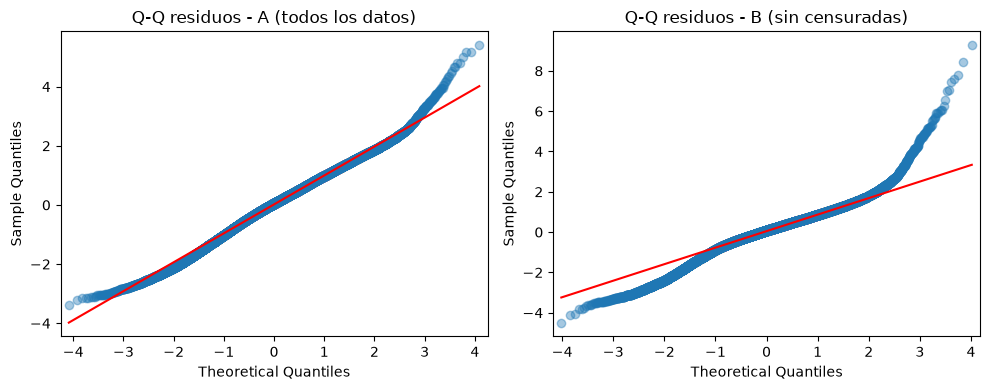

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, (tr, va)) in zip(axes, escenarios.items()):
    residuos = LinearRegression().fit(tr[variables], tr["Prima"]).predict(tr[variables]) - tr["Prima"]
    sm.qqplot(residuos, fit=True, line="q", ax=ax, alpha=0.4, lw=2)
    ax.set_title(f"Q-Q residuos - {nombre}")
plt.tight_layout()
plt.show()

| Supuesto | Cómo | Resultado (A y B) |
|---|---|---|
| Normalidad | Histograma, Q-Q y test | No se cumple: p-valor 0 y colas separadas de la recta. |
| Homocedasticidad | Residuos vs predicción | No se cumple: banda curvada, no una nube uniforme. |
| Independencia | Durbin-Watson | Se cumple: 2,00. |
| No multicolinealidad | Matriz de 4.3 | Se cumple: máximo 0,59. |

En A los censurados forman columnas en 400, 580, 760 y 800 € y líneas rectas en los residuos. El modelo da primas negativas y de hasta 1.500 €. Los residuos siguen un patrón curvo: la relación no es lineal y hace falta un modelo que ajuste curvas.

## 6. Descenso de gradiente

La ecuación normal invierte $X^T X$, que es costoso con muchas variables (en el apartado 7 habrá cientos). El descenso de gradiente llega a los mismos coeficientes poco a poco:

1. Empezar con coeficientes 0.
2. Calcular el gradiente del error: $\nabla MSE = \frac{2}{m} X^T (X\beta - y)$.
3. Dar un paso en sentido contrario: $\beta = \beta - \eta \nabla MSE$.
4. Repetir hasta que el error deje de bajar.

La tasa de aprendizaje $\eta$ marca el tamaño del paso: si es pequeña tarda mucho; si es grande se pasa del mínimo y diverge. Las variables deben estar estandarizadas.

### 6.1 Descenso de gradiente programado paso a paso

Modelo lineal del escenario A con tres tasas, comparado con la ecuación normal.

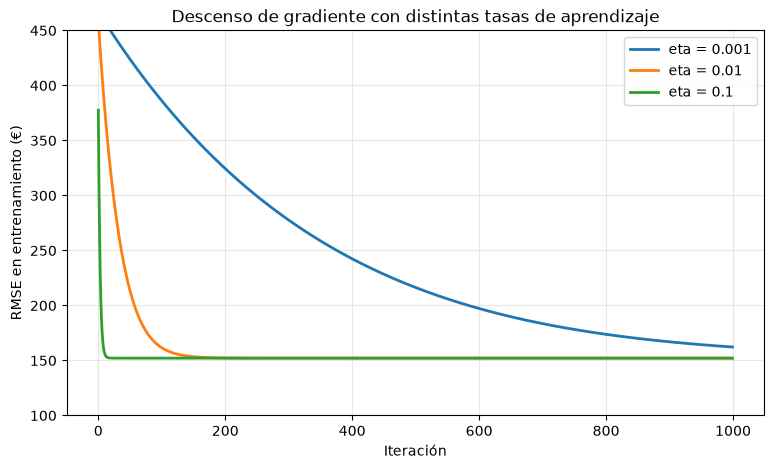

In [72]:
tr, va = escenarios["A (todos los datos)"]

X_gd = StandardScaler().fit_transform(tr[variables])
X_gd = np.c_[np.ones(len(X_gd)), X_gd]   # añadimos la columna de unos del intercepto
y_gd = tr["Prima"].values
m = len(y_gd)

plt.figure(figsize=(9, 5))
coeficientes_gd = {}
for eta in [0.001, 0.01, 0.1]:
    beta = np.zeros(X_gd.shape[1])          # 1) empezamos con todos los coeficientes a 0
    historial = []
    for iteracion in range(1000):
        gradiente = 2 / m * X_gd.T @ (X_gd @ beta - y_gd)   # 2) gradiente del MSE
        beta = beta - eta * gradiente                         # 3) paso en la dirección contraria
        historial.append(np.sqrt(np.mean((X_gd @ beta - y_gd) ** 2)))
    coeficientes_gd[f"Descenso de gradiente (eta = {eta})"] = beta
    plt.plot(historial, linewidth=2, label=f"eta = {eta}")

plt.xlabel("Iteración")
plt.ylabel("RMSE en entrenamiento (€)")
plt.title("Descenso de gradiente con distintas tasas de aprendizaje")
plt.ylim(100, 450)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [73]:
# Solución exacta con la ecuación normal (LinearRegression) sobre las mismas variables estandarizadas
ecuacion_normal = LinearRegression().fit(X_gd[:, 1:], y_gd)
coeficientes_gd["Ecuación normal"] = np.r_[ecuacion_normal.intercept_, ecuacion_normal.coef_]

pd.DataFrame(coeficientes_gd, index=["Intercepto"] + variables).round(2)

,Descenso de gradiente (eta = 0.001),Descenso de gradiente (eta = 0.01),Descenso de gradiente (eta = 0.1),Ecuación normal
Intercepto,332.14,384.01,384.01,384.01
Monto_Inicial,96.73,96.67,96.65,96.65
Duracion,71.45,82.73,82.73,82.73
Scoring_Crediticio,-43.68,-58.62,-58.62,-58.62
Ratio_Interes,30.63,35.59,35.59,35.59
Ratio_Deuda_Ingresos,110.18,124.24,124.26,124.26
Ingresos,29.90,31.15,31.16,31.16


- eta = 0,1 converge en pocas iteraciones y eta = 0,01 en unas 200; los dos dan exactamente los coeficientes de la ecuación normal.
- eta = 0,001 no llega en 1.000 iteraciones (intercepto 332 en vez de 384).

Los coeficientes son de variables estandarizadas (euros por desviación típica), así que se pueden comparar: mayor efecto del Ratio_Deuda_Ingresos (124 €), Monto_Inicial (97 €) y Duracion (83 €).

### 6.2 Descenso de gradiente estocástico

Usa un solo préstamo al azar en cada paso: más rápido, pero irregular. Con tasa fija oscila alrededor del mínimo sin asentarse, así que conviene ir bajando la tasa (programación del aprendizaje). En SGDRegressor, eta0 es la tasa inicial y learning_rate la programación:

- "constant": siempre eta0.
- "invscaling" (por defecto): baja poco a poco.
- "adaptive": la divide entre 5 cada vez que el error deja de bajar.

In [74]:
scaler_gd = StandardScaler().fit(tr[variables])
X_tr_gd = scaler_gd.transform(tr[variables])
X_va_gd = scaler_gd.transform(va[variables])

resultados_sgd = []
for learning_rate in ["constant", "invscaling", "adaptive"]:
    sgd = SGDRegressor(learning_rate=learning_rate, eta0=0.01, max_iter=1000, random_state=42)
    sgd.fit(X_tr_gd, tr["Prima"])
    prediccion = np.clip(sgd.predict(X_va_gd), 10, va["Tope"])
    resultados_sgd.append([learning_rate, sgd.n_iter_, root_mean_squared_error(va["Prima"], prediccion)])

prediccion = np.clip(ecuacion_normal.predict(X_va_gd), 10, va["Tope"])
resultados_sgd.append(["Ecuación normal", None, root_mean_squared_error(va["Prima"], prediccion)])

pd.DataFrame(resultados_sgd, columns=["metodo", "pasadas_por_los_datos", "RMSE_validacion"]).round(2)

,metodo,pasadas_por_los_datos,RMSE_validacion
0,constant,8.0,167.44
1,invscaling,24.0,142.79
2,adaptive,67.0,142.56
3,Ecuación normal,NaN,142.55


- "constant": para a las 8 pasadas en 167,4 €, 25 € peor que la ecuación normal, porque con tasa fija oscila sin asentarse.
- "invscaling" (142,79 €, en 24 pasadas) y "adaptive" (142,56 €, en 67) llegan al resultado de la ecuación normal (142,55 €).

## 7. Regresión polinómica
### 7.1 Elección del grado

Añade potencias y combinaciones de las variables (Monto², Monto × Duración...) para ajustar curvas. Sigue siendo lineal en los coeficientes. Más grado es más flexibilidad, pero más riesgo de sobreajuste (memorizar el ruido).

Estandarizamos antes del polinomio para que las potencias no tengan tamaños muy distintos. El grado se elige con validación cruzada de 5 particiones, que no depende de un solo reparto de los datos. También mostramos el error en validación con y sin recorte.

In [75]:
tablas_grados = []
for nombre, (tr, va) in escenarios.items():
    scaler = StandardScaler()
    X_tr_esc = scaler.fit_transform(tr[variables])
    X_va_esc = scaler.transform(va[variables])

    for grado in [1, 2, 3, 4, 5, 6]:
        poly = PolynomialFeatures(degree=grado, include_bias=False)
        X_tr = poly.fit_transform(X_tr_esc)
        X_va = poly.transform(X_va_esc)

        modelo = LinearRegression().fit(X_tr, tr["Prima"])
        rmse_train = root_mean_squared_error(tr["Prima"], modelo.predict(X_tr))
        rmse_cv = -cross_val_score(LinearRegression(), X_tr, tr["Prima"], cv=5, scoring="neg_root_mean_squared_error").mean()
        rmse_val = root_mean_squared_error(va["Prima"], modelo.predict(X_va))
        rmse_val_recortado = root_mean_squared_error(va["Prima"], np.clip(modelo.predict(X_va), 10, va["Tope"]))
        tablas_grados.append([nombre, grado, X_tr.shape[1], rmse_train, rmse_cv, rmse_val, rmse_val_recortado])

tablas_grados = pd.DataFrame(tablas_grados, columns=["escenario", "grado", "num_terminos", "RMSE_train", "RMSE_cv",
                                                     "RMSE_val_sin_recortar", "RMSE_val_recortado"])
tablas_grados["diferencia_cv_train"] = tablas_grados["RMSE_cv"] - tablas_grados["RMSE_train"]
tablas_grados.round(2)

,escenario,grado,num_terminos,RMSE_train,RMSE_cv,RMSE_val_sin_recortar,RMSE_val_recortado,diferencia_cv_train
0,A (todos los datos),1,6,152.14,152.16,151.02,142.55,0.03
1,A (todos los datos),2,27,97.58,97.69,98.46,90.53,0.11
2,A (todos los datos),3,83,75.40,75.63,76.09,71.15,0.22
3,A (todos los datos),4,209,64.45,65.16,65.45,62.48,0.71
4,A (todos los datos),5,461,57.91,59.30,59.40,57.61,1.39
5,A (todos los datos),6,923,54.23,57.71,57.43,55.41,3.48
6,B (sin censuradas),1,6,101.66,101.68,100.66,94.37,0.02
7,B (sin censuradas),2,27,68.24,68.34,68.58,67.05,0.10
8,B (sin censuradas),3,83,61.81,62.00,61.88,61.66,0.19
9,B (sin censuradas),4,209,57.19,57.73,57.55,57.46,0.53


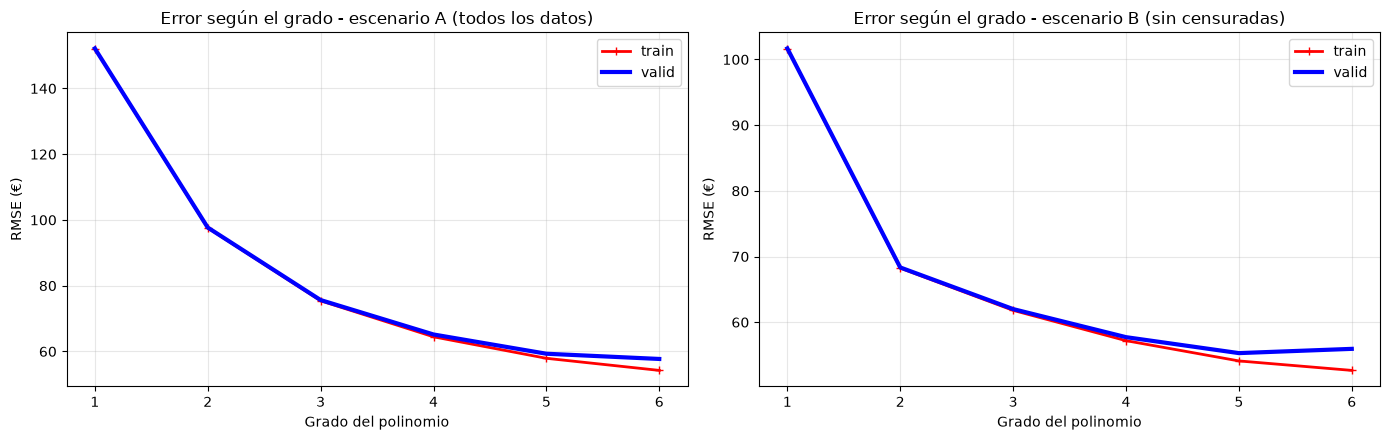

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, nombre in zip(axes, escenarios):
    t = tablas_grados[tablas_grados["escenario"] == nombre]
    ax.plot(t["grado"], t["RMSE_train"], "r-+", linewidth=2, label="train")
    ax.plot(t["grado"], t["RMSE_cv"], "b-", linewidth=3, label="valid")
    ax.set_xlabel("Grado del polinomio")
    ax.set_ylabel("RMSE (€)")
    ax.set_title(f"Error según el grado - escenario {nombre}")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Sobreajuste: bien en entrenamiento y mal en validación. Subajuste: mal en los dos.

- Grado 1: 152 € en A y 102 € en B en los dos errores. Subajuste.
- El error baja con el grado: en A, 76 € (grado 3), 65 € (4) y 59 € (5).
- Grado 6: en A solo baja 1,6 €, pero con el doble de términos (923) y la diferencia con entrenamiento de 1,4 € a 3,5 €. En B el error ya sube (55,3 € a 55,9 €). Señales de sobreajuste.

Elegimos grado 5 en los dos escenarios (parsimonia).

Recortar las predicciones baja el error en validación en A de 59,4 € a 57,6 € (con la recta, de 151,0 € a 142,6 €). En B apenas cambia, porque su validación no tiene préstamos en los límites.

### 7.2 Comprobación de las variables con el polinomio de grado 5

Las variables se eligieron con modelos lineales; con curvas y combinaciones podría aportar alguna otra. Con grado 5 quitamos cada una de las 6 y añadimos cada una de las demás (las categóricas con todas sus columnas), y medimos el cambio en el error de validación.

In [77]:
extras = {
    "Probabilidad_Impago": ["Probabilidad_Impago"],
    "Edad": ["Edad"],
    "Meses_Empleo": ["Meses_Empleo"],
    "Num_Creditos": ["Num_Creditos"],
    "Posesion_Hipoteca": ["Posesion_Hipoteca"],
    "Personas_Cargo": ["Personas_Cargo"],
    "Fiador": ["Fiador"],
    "Estudios": ["Estudios_Escolar", "Estudios_Grado Universitario", "Estudios_Máster"],
    "Tipo_Jornada_Laboral": ["Tipo_Jornada_Laboral_Desempleado", "Tipo_Jornada_Laboral_Jornada completa",
                             "Tipo_Jornada_Laboral_Tiempo parcial"],
    "Estado_Civil": ["Estado_Civil_Divorciado", "Estado_Civil_Soltero"],
}
pruebas = {"6 variables": variables}
for v in variables:
    pruebas["- " + v] = [x for x in variables if x != v]
for nombre, columnas in extras.items():
    pruebas["+ " + nombre] = variables + columnas

comprobacion = []
for nombre_esc, (tr, va) in escenarios.items():
    for nombre, columnas in pruebas.items():
        scaler = StandardScaler()
        poly = PolynomialFeatures(degree=5, include_bias=False)
        X_tr = poly.fit_transform(scaler.fit_transform(tr[columnas]))
        X_va = poly.transform(scaler.transform(va[columnas]))
        modelo = LinearRegression().fit(X_tr, tr["Prima"])
        prediccion = np.clip(modelo.predict(X_va), 10, va["Tope"])
        comprobacion.append([nombre_esc, nombre, X_tr.shape[1], root_mean_squared_error(va["Prima"], prediccion)])

comprobacion = pd.DataFrame(comprobacion, columns=["escenario", "prueba", "num_terminos", "RMSE_validacion"])
base = comprobacion[comprobacion["prueba"] == "6 variables"].set_index("escenario")["RMSE_validacion"]
comprobacion["cambio_vs_6_variables"] = comprobacion["RMSE_validacion"] - comprobacion["escenario"].map(base)
comprobacion.pivot_table(index="prueba", columns="escenario", values=["num_terminos", "cambio_vs_6_variables"],
                         sort=False).round(2)

num_terminos                     \
escenario              A (todos los datos) B (sin censuradas)   
prueba                                                          
6 variables                          461.0              461.0   
- Monto_Inicial                      251.0              251.0   
- Duracion                           251.0              251.0   
- Scoring_Crediticio                 251.0              251.0   
- Ratio_Interes                      251.0              251.0   
- Ratio_Deuda_Ingresos               251.0              251.0   
- Ingresos                           251.0              251.0   
+ Probabilidad_Impago                791.0              791.0   
+ Edad                               791.0              791.0   
+ Meses_Empleo                       791.0              791.0   
+ Num_Creditos                       791.0              791.0   
+ Posesion_Hipoteca                  791.0              791.0   
+ Personas_Cargo                     791.0              791.0   
+ Fiador                             791.0              791.0   
+ Estudios                          2001.0             2001.0   
+ Tipo_Jornada_Laboral              2001.0             2001.0   
+ Estado_Civil                      1286.0             1286.0   

                       cambio_vs_6_variables                     
escenario                A (todos los datos) B (sin censuradas)  
prueba                                                           
6 variables                             0.00               0.00  
- Monto_Inicial                        89.42              74.98  
- Duracion                             36.77              33.69  
- Scoring_Crediticio                   46.78              44.20  
- Ratio_Interes                        17.93              18.00  
- Ratio_Deuda_Ingresos                  5.52               2.03  
- Ingresos                              2.29               1.70  
+ Probabilidad_Impago                  -0.10               0.15  
+ Edad                                  0.05               0.16  
+ Meses_Empleo                         -0.13               0.13  
+ Num_Creditos                          0.14               0.21  
+ Posesion_Hipoteca                     0.20               0.39  
+ Personas_Cargo                        0.16               0.43  
+ Fiador                                0.19               0.28  
+ Estudios                             -0.23               0.01  
+ Tipo_Jornada_Laboral                  0.95               0.85  
+ Estado_Civil                          0.55               0.48

- Quitar cualquiera de las 6 empeora el error en los dos escenarios: Monto_Inicial +89 € (en A), Scoring_Crediticio +47 €, Duracion +37 €, Ratio_Interes +18 €, Ratio_Deuda_Ingresos +5,5 € e Ingresos +2,3 € (+1,7 € en B).
- Añadir otra mejora como mucho 0,23 € en A (Estudios, a cambio de pasar de 461 a 2.001 términos; Meses_Empleo 0,13 € y Probabilidad_Impago 0,10 €, con 791). En B ninguna mejora.

Se confirman las mismas 6 variables.

### 7.3 Curvas de aprendizaje

Error de entrenamiento y validación según la cantidad de datos. Curvas juntas en un error alto: subajuste. Espacio entre ellas: sobreajuste.

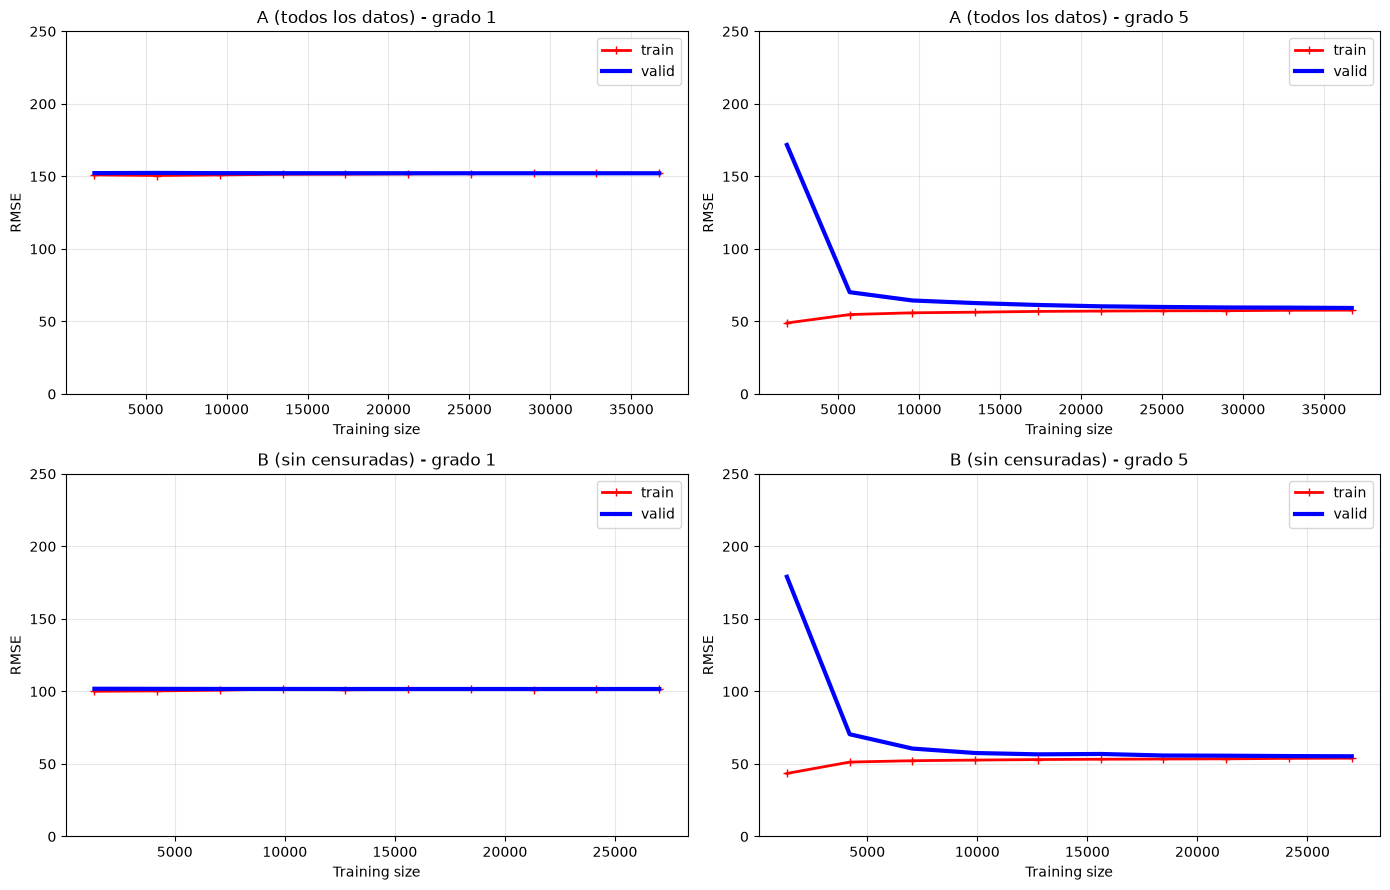

In [78]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for fila, (nombre, (tr, va)) in enumerate(escenarios.items()):
    X_tr_esc = StandardScaler().fit_transform(tr[variables])
    for col, grado in enumerate([1, 5]):
        X_tr = PolynomialFeatures(degree=grado, include_bias=False).fit_transform(X_tr_esc)
        train_sizes, train_scores, valid_scores = learning_curve(LinearRegression(), X_tr, tr["Prima"],
                                                                 train_sizes=np.linspace(0.05, 1.0, 10), cv=5,
                                                                 scoring="neg_root_mean_squared_error")
        ax = axes[fila, col]
        ax.plot(train_sizes, -train_scores.mean(axis=1), "r-+", linewidth=2, label="train")
        ax.plot(train_sizes, -valid_scores.mean(axis=1), "b-", linewidth=3, label="valid")
        ax.set_ylim(0, 250)
        ax.set_xlabel("Training size")
        ax.set_ylabel("RMSE")
        ax.set_title(f"{nombre} - grado {grado}")
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- Grado 1: las curvas se juntan enseguida en un error alto. Subajuste (mucho sesgo); más datos no ayudan.
- Grado 5: con pocos datos hay sobreajuste, pero el espacio se cierra al añadir datos (unos 59 € en A y 55 € en B). Con los datos que tenemos generaliza bien.

Es el compromiso sesgo-varianza: el grado 5 reduce mucho el sesgo sin que la varianza sea un problema.

## 8. Regularización

Añade al error una penalización por el tamaño de los coeficientes, para limitar el sobreajuste. Más alpha es más penalización. Volvemos a estandarizar tras el polinomio, porque las potencias no están en la misma escala.

In [79]:
def preparar(d, X):
    # estandarizar, crear el polinomio de grado 5 y volver a estandarizar
    return d["scaler_poly"].transform(d["poly"].transform(d["scaler"].transform(X[variables])))

def error_val(modelo, d):
    # RMSE en validación con las predicciones recortadas entre 10 € y el tope
    return root_mean_squared_error(d["y_va"], np.clip(modelo.predict(d["X_va"]), 10, d["tope_va"]))

# Preparamos los datos de grado 5 de cada escenario
datos_poly = {}
for nombre, (tr, va) in escenarios.items():
    scaler = StandardScaler().fit(tr[variables])
    poly = PolynomialFeatures(degree=5, include_bias=False).fit(scaler.transform(tr[variables]))
    scaler_poly = StandardScaler().fit(poly.transform(scaler.transform(tr[variables])))
    d = {"scaler": scaler, "poly": poly, "scaler_poly": scaler_poly}
    d.update({"X_tr": preparar(d, tr), "y_tr": tr["Prima"], "X_va": preparar(d, va), "y_va": va["Prima"],
              "tope_va": va["Tope"]})
    datos_poly[nombre] = d

### 8.1 Ridge

Penaliza la suma de los coeficientes al cuadrado; los reduce sin llevarlos a 0. Alpha con RidgeCV.

A (todos los datos): alpha elegido por RidgeCV = 0.0489
B (sin censuradas): alpha elegido por RidgeCV = 2.3950


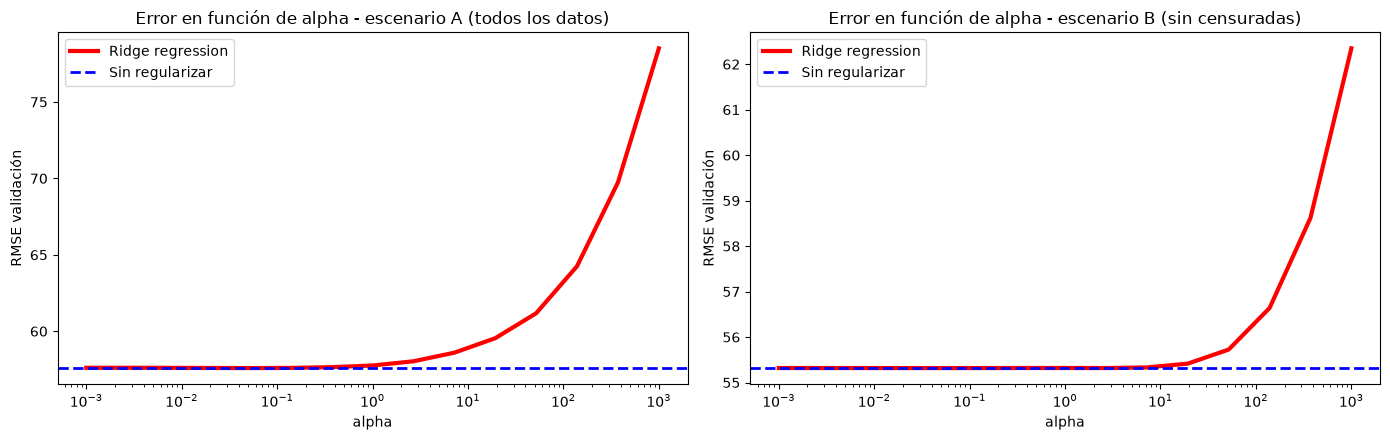

In [80]:
alpha_ridgecv = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, (nombre, d) in zip(axes, datos_poly.items()):
    modelo_ridgecv = RidgeCV(alphas=np.logspace(-3, 4, 30), cv=5).fit(d["X_tr"], d["y_tr"])
    alpha_ridgecv[nombre] = modelo_ridgecv.alpha_
    error_lineal = error_val(LinearRegression().fit(d["X_tr"], d["y_tr"]), d)

    alphas = np.logspace(-3, 3, 15)
    err_ridge = [error_val(Ridge(alpha=a).fit(d["X_tr"], d["y_tr"]), d) for a in alphas]

    print(f"{nombre}: alpha elegido por RidgeCV = {modelo_ridgecv.alpha_:.4f}")
    ax.plot(alphas, err_ridge, linewidth=3, color="red", label="Ridge regression")
    ax.axhline(error_lineal, linewidth=2, linestyle="--", color="blue", label="Sin regularizar")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("RMSE validación")
    ax.set_title(f"Error en función de alpha - escenario {nombre}")
    ax.legend()

plt.tight_layout()
plt.show()

### 8.2 Lasso y Elastic Net

Lasso penaliza la suma de valores absolutos y puede llevar coeficientes a 0. Elastic Net combina las dos penalizaciones (l1_ratio es el peso de Lasso).

Se ajustan de forma iterativa, muy lenta con alphas pequeños. Con precompute=True se calcula $X^T X$ una sola vez, y así podemos probar alphas desde 0,001.

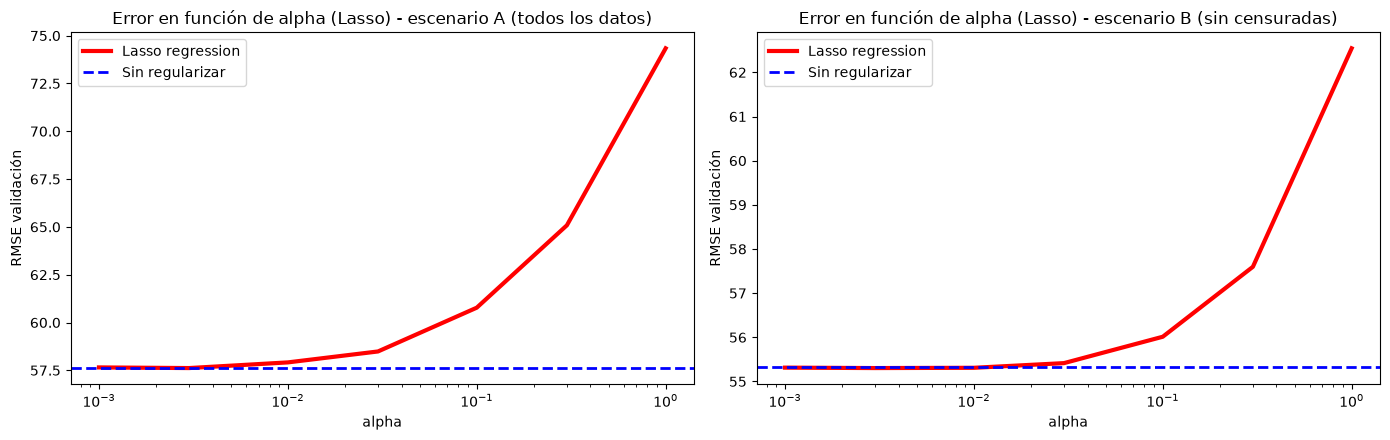

terminos_distintos_de_0                        RMSE_validacion  \
escenario     A (todos los datos) B (sin censuradas) A (todos los datos)   
alpha                                                                      
0.001                       455.0              450.0               57.65   
0.003                       449.0              442.0               57.62   
0.01                        414.0              406.0               57.92   
0.03                        371.0              361.0               58.49   
0.1                         302.0              259.0               60.78   
0.3                         189.0              151.0               65.08   
1.0                         107.0               90.0               74.34   

                              
escenario B (sin censuradas)  
alpha                         
0.001                  55.31  
0.003                  55.30  
0.01                   55.31  
0.03                   55.42  
0.1                    56.01  
0.3                    57.60  
1.0                    62.54

In [81]:
alphas_lasso = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]
tabla_lasso = []
for nombre, d in datos_poly.items():
    for a in alphas_lasso:
        lasso = Lasso(alpha=a, max_iter=100000, precompute=True).fit(d["X_tr"], d["y_tr"])
        tabla_lasso.append([nombre, a, (lasso.coef_ != 0).sum(), error_val(lasso, d)])
tabla_lasso = pd.DataFrame(tabla_lasso, columns=["escenario", "alpha", "terminos_distintos_de_0", "RMSE_validacion"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (nombre, d) in zip(axes, datos_poly.items()):
    t = tabla_lasso[tabla_lasso["escenario"] == nombre]
    ax.plot(t["alpha"], t["RMSE_validacion"], linewidth=3, color="red", label="Lasso regression")
    ax.axhline(error_val(LinearRegression().fit(d["X_tr"], d["y_tr"]), d), linewidth=2, linestyle="--", color="blue",
               label="Sin regularizar")
    ax.set_xscale("log")
    ax.set_xlabel("alpha")
    ax.set_ylabel("RMSE validación")
    ax.set_title(f"Error en función de alpha (Lasso) - escenario {nombre}")
    ax.legend()
plt.tight_layout()
plt.show()

tabla_lasso["alpha"] = tabla_lasso["alpha"].astype(str)
tabla_lasso.pivot_table(index="alpha", columns="escenario", values=["terminos_distintos_de_0", "RMSE_validacion"],
                        sort=False).round(2)

Alpha elegido por validación cruzada, comparado con Ridge y sin regularizar:

In [82]:
comparacion = []
for nombre, d in datos_poly.items():
    sin_reg = LinearRegression().fit(d["X_tr"], d["y_tr"])
    ridge = Ridge(alpha=alpha_ridgecv[nombre]).fit(d["X_tr"], d["y_tr"])
    lassocv = LassoCV(alphas=np.logspace(-3, 0, 10), cv=5, max_iter=100000, precompute=True,
                      n_jobs=-1).fit(d["X_tr"], d["y_tr"])
    enetcv = ElasticNetCV(alphas=np.logspace(-3, 0, 10), l1_ratio=[0.1, 0.5, 0.9], cv=5, max_iter=100000,
                          precompute=True, n_jobs=-1).fit(d["X_tr"], d["y_tr"])

    for metodo, modelo in [("Sin regularizar", sin_reg), (f"Ridge (alpha={alpha_ridgecv[nombre]:.4f})", ridge),
                           (f"Lasso (alpha={lassocv.alpha_:.4f})", lassocv),
                           (f"Elastic Net (alpha={enetcv.alpha_:.4f}, l1_ratio={enetcv.l1_ratio_})", enetcv)]:
        comparacion.append([nombre, metodo, (modelo.coef_ != 0).sum(), error_val(modelo, d)])

pd.DataFrame(comparacion, columns=["escenario", "modelo", "terminos_distintos_de_0", "RMSE_validacion"]).round(2)

,escenario,modelo,terminos_distintos_de_0,RMSE_validacion
0,A (todos los datos),Sin regularizar,461,57.61
1,A (todos los datos),Ridge (alpha=0.0489),461,57.59
2,A (todos los datos),Lasso (alpha=0.0010),455,57.65
3,A (todos los datos),"Elastic Net (alpha=0.0010, l1_ratio=0.9)",456,58.33
4,B (sin censuradas),Sin regularizar,461,55.32
5,B (sin censuradas),Ridge (alpha=2.3950),461,55.32
6,B (sin censuradas),Lasso (alpha=0.0100),406,55.31
7,B (sin censuradas),"Elastic Net (alpha=0.0010, l1_ratio=0.9)",456,55.31


- Ridge: RidgeCV elige alpha = 0,049 en A y 2,4 en B, con el mismo error que sin regularizar (57,59 € frente a 57,61 € en A); al subir más alpha, empeora.
- Lasso: al subir alpha quita términos y el error sube (en A, 414 términos y 57,92 € con 0,01; 302 y 60,78 € con 0,1). LassoCV elige 0,001 en A (455 términos, 57,65 €) y 0,01 en B (55,31 €). No elimina ninguna de las 6 variables, solo combinaciones.
- Elastic Net: casi todo Lasso (l1_ratio 0,9) e igual o algo peor (58,33 € en A).

Ninguna mejora de forma apreciable, porque el grado 5 casi no se sobreajusta (1,4 € de diferencia, como mostraban las curvas). Mantenemos Ridge: es la única que no empeora en ningún escenario y estabiliza los coeficientes de términos muy correlacionados (x⁴ y x⁵).

### 8.3 Ridge con descenso de gradiente estocástico

SGDRegressor(penalty="l2") ajusta Ridge con descenso de gradiente. Para compararlo con la solución exacta:

1. Misma penalización: Ridge usa la suma de errores y SGDRegressor la media (dividida entre n). Por eso su alpha debe ser el de Ridge entre n; con el mismo número penalizaría n veces más (unas 46.000 en A).
2. Tasa y programación: algunos préstamos tienen valores extremos en las potencias altas y un paso con ellos puede disparar los coeficientes. Probamos las tres programaciones con varias tasas.

In [83]:
comparacion_sgd = []
for nombre, d in datos_poly.items():
    n = len(d["y_tr"])
    alpha_sgd = alpha_ridgecv[nombre] / n
    print(f"{nombre}: alpha de Ridge = {alpha_ridgecv[nombre]:.4f} -> alpha de SGDRegressor = {alpha_sgd:.2e}")

    ridge_exacto = Ridge(alpha=alpha_ridgecv[nombre]).fit(d["X_tr"], d["y_tr"])
    comparacion_sgd.append([nombre, "Ridge (solución exacta)", "-", None, error_val(ridge_exacto, d)])

    for learning_rate, eta0 in [("constant", 0.0001), ("constant", 0.00001), ("invscaling", 0.001),
                                ("invscaling", 0.0005), ("adaptive", 0.0001), ("adaptive", 0.00001)]:
        sgd = SGDRegressor(penalty="l2", alpha=alpha_sgd, learning_rate=learning_rate, eta0=eta0, max_iter=1000,
                           random_state=42)
        sgd.fit(d["X_tr"], d["y_tr"])
        comparacion_sgd.append([nombre, f"SGDRegressor ({learning_rate})", str(eta0), sgd.n_iter_, error_val(sgd, d)])

tabla_sgd = pd.DataFrame(comparacion_sgd, columns=["escenario", "modelo", "eta0", "pasadas_por_los_datos", "RMSE_validacion"])
tabla_sgd["RMSE_validacion"] = tabla_sgd["RMSE_validacion"].round(2)
tabla_sgd

A (todos los datos): alpha de Ridge = 0.0489 -> alpha de SGDRegressor = 1.07e-06
B (sin censuradas): alpha de Ridge = 2.3950 -> alpha de SGDRegressor = 7.09e-05


,escenario,modelo,eta0,pasadas_por_los_datos,RMSE_validacion
0,A (todos los datos),Ridge (solución exacta),-,NaN,57.59
1,A (todos los datos),SGDRegressor (constant),0.0001,6.0,436.61
2,A (todos los datos),SGDRegressor (constant),1e-05,808.0,61.62
3,A (todos los datos),SGDRegressor (invscaling),0.001,114.0,66.49
4,A (todos los datos),SGDRegressor (invscaling),0.0005,838.0,62.09
5,A (todos los datos),SGDRegressor (adaptive),0.0001,21.0,439.79
6,A (todos los datos),SGDRegressor (adaptive),1e-05,879.0,61.66
7,B (sin censuradas),Ridge (solución exacta),-,NaN,55.32
8,B (sin censuradas),SGDRegressor (constant),0.0001,6.0,331.25
9,B (sin censuradas),SGDRegressor (constant),1e-05,333.0,57.36


- Con eta0 = 0,0001 diverge ("constant" y "adaptive"): error de más de 300 €. En B, "invscaling" también falla (220 € con 0,001 y 80 € con 0,0005, porque para a las 7 pasadas).
- Con tasas estables, lo mejor en A es "constant" con 0,00001 (61,62 €) y "adaptive" con 0,00001 (61,66 €); "invscaling" da entre 62,1 € y 66,5 €. En B, lo mejor es "adaptive" con 0,00001 (56,58 €), que agota las 1.000 pasadas.
- Ridge exacto: 57,59 € en A y 55,32 € en B.

Con la misma penalización, la diferencia (4 € en A) se debe a que el descenso de gradiente no llega al mínimo: los términos correlacionados obligan a pasos muy pequeños. Con 461 términos la ecuación normal es viable y más precisa, así que el modelo final la usa.

## 9. Búsqueda de hiperparámetros

Los hiperparámetros se fijan antes de entrenar (los coeficientes se aprenden). El grado se eligió en el apartado 7 y la tasa de aprendizaje en 6 y 8.3. Para alpha:

- Grid Search: prueba todos los valores de una lista.
- Random Search: prueba valores al azar de una distribución; cubre más rango con las mismas pruebas.

(Errores sin recortar, por eso algo mayores que en el apartado 8.)

In [84]:
mejores_alpha = {}
for nombre, d in datos_poly.items():
    print("=" * 30, nombre, "=" * 30)

    # Grid Search con Ridge
    reg_pol = Ridge()
    hyperparameter = {"alpha": [0.001, 0.01, 0.1, 1, 10, 100]}
    grid = GridSearchCV(estimator=reg_pol, param_grid=hyperparameter, cv=5, scoring="neg_root_mean_squared_error")
    grid.fit(d["X_tr"], d["y_tr"])
    print("Grid Search (Ridge):", grid.best_params_, round(-grid.best_score_, 2))
    print(pd.DataFrame({"alpha": [str(a) for a in hyperparameter["alpha"]],
                        "RMSE_cv": -grid.cv_results_["mean_test_score"]}).round(2).to_string(index=False))
    mejores_alpha[nombre] = grid.best_params_["alpha"]

    # Random Search con Lasso
    reg_lasso = Lasso(max_iter=100000, precompute=True)
    hyperparameter = {"alpha": loguniform(0.001, 1)}   # valores entre 0,001 y 1 repartidos en escala logarítmica
    random = RandomizedSearchCV(estimator=reg_lasso, param_distributions=hyperparameter, n_iter=8, cv=5,
                                scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1)
    random.fit(d["X_tr"], d["y_tr"])
    print("Random Search (Lasso): alpha =", round(random.best_params_["alpha"], 4), " RMSE_cv =", round(-random.best_score_, 2))
    print()

============================== A (todos los datos) ==============================
Grid Search (Ridge): {'alpha': 0.1} 59.27
alpha  RMSE_cv
0.001    59.29
 0.01    59.27
  0.1    59.27
    1    59.60
   10    61.20
  100    66.05
Random Search (Lasso): alpha = 0.0015  RMSE_cv = 59.31

============================== B (sin censuradas) ==============================
Grid Search (Ridge): {'alpha': 1} 55.29
alpha  RMSE_cv
0.001    55.30
 0.01    55.30
  0.1    55.30
    1    55.29
   10    55.33
  100    56.63
Random Search (Lasso): alpha = 0.0133  RMSE_cv = 55.22



- Grid Search (Ridge): alpha = 0,1 en A (59,27 €, empatado con 0,01) y 1 en B (55,29 €). Las diferencias entre alphas pequeños son de céntimos; el error sube a partir de 10.
- Random Search (Lasso): 0,0015 en A (59,31 €, algo peor que Ridge) y 0,013 en B (55,22 €, 7 céntimos mejor).

Mantenemos Ridge en los dos (diferencias despreciables y no elimina términos): grado 5 con Ridge, alpha = 0,1 en A y 1 en B.

## 10. Elección del escenario en validación y evaluación final en test
### 10.1 Elección del escenario con la validación completa

Comparamos el modelo final de cada escenario en la validación completa, separando censurados y no censurados. El lineal se incluye como referencia.

In [85]:
modelos_finales = {}
for nombre, d in datos_poly.items():
    modelos_finales[nombre] = Ridge(alpha=mejores_alpha[nombre]).fit(d["X_tr"], d["y_tr"])

grupos_val = {
    "Validación completa": val,
    "No censuradas": val[~val["Censurada"]],
    "Censuradas": val[val["Censurada"]],
}

resultados_val = []
for nombre, (tr, va) in escenarios.items():
    lineal = LinearRegression().fit(tr[variables], tr["Prima"])
    for nombre_grupo, g in grupos_val.items():
        pred_lineal = np.clip(lineal.predict(g[variables]), 10, g["Tope"])
        pred_final = np.clip(modelos_finales[nombre].predict(preparar(datos_poly[nombre], g)), 10, g["Tope"])
        resultados_val.append([nombre, "Lineal", nombre_grupo, root_mean_squared_error(g["Prima"], pred_lineal),
                               mean_absolute_error(g["Prima"], pred_lineal)])
        resultados_val.append([nombre, "Polinomio grado 5 + Ridge", nombre_grupo,
                               root_mean_squared_error(g["Prima"], pred_final), mean_absolute_error(g["Prima"], pred_final)])

resultados_val = pd.DataFrame(resultados_val, columns=["escenario", "modelo", "grupo", "RMSE", "MAE"])
resultados_val.pivot_table(index=["escenario", "modelo"], columns="grupo", values=["RMSE", "MAE"]).round(2)

MAE                \
grupo                                         Censuradas No censuradas   
escenario           modelo                                               
A (todos los datos) Lineal                        115.14        106.32   
                    Polinomio grado 5 + Ridge      31.20         42.43   
B (sin censuradas)  Lineal                         74.93         70.21   
                    Polinomio grado 5 + Ridge     168.47         38.92   

                                                                        RMSE  \
grupo                                         Validación completa Censuradas   
escenario           modelo                                                     
A (todos los datos) Lineal                                 108.68     161.43   
                    Polinomio grado 5 + Ridge               39.43      55.72   
B (sin censuradas)  Lineal                                  71.47     131.37   
                    Polinomio grado 5 + Ridge               73.58     281.15   

                                                             \
grupo                                         No censuradas   
escenario           modelo                                    
A (todos los datos) Lineal                           135.00   
                    Polinomio grado 5 + Ridge         58.27   
B (sin censuradas)  Lineal                            94.37   
                    Polinomio grado 5 + Ridge         55.32   

                                                                   
grupo                                         Validación completa  
escenario           modelo                                         
A (todos los datos) Lineal                                 142.55  
                    Polinomio grado 5 + Ridge               57.60  
B (sin censuradas)  Lineal                                 105.55  
                    Polinomio grado 5 + Ridge              152.93

| Validación | A (RMSE / MAE) | B (RMSE / MAE) |
|---|---|---|
| No censuradas | 58,3 € / 42,4 € | 55,3 € / 38,9 € |
| Censuradas | 55,7 € / 31,2 € | 281,2 € / 168,5 € |
| Completa | 57,6 € / 39,4 € | 152,9 € / 73,6 € |

B es algo mejor en los no censurados, pero falla muchísimo en los censurados: nunca ha visto primas en el tope y tiene que extrapolar. Con el modelo lineal pasa lo contrario (B 105,6 € y A 142,6 €), pero la elección se hace con el modelo que vamos a usar.

Decisión: escenario A. Uno de cada cuatro préstamos queda en un límite, y para un cliente nuevo no se sabe de antemano. El test sigue sin usarse.

### 10.2 Evaluación final en test

Modelo final (escenario A), evaluado una sola vez, con y sin recorte y por grupos.

In [86]:
final = datos_poly["A (todos los datos)"]
modelo_final = modelos_finales["A (todos los datos)"]
modelo_lineal = LinearRegression().fit(train[variables], train["Prima"])

def predecir(X):
    # prima estimada por el modelo final, recortada entre 10 € y el tope de su duración
    return np.clip(modelo_final.predict(preparar(final, X)), 10, X["Duracion"].map(topes))

grupos_test = {
    "Test completo": test,
    "No censuradas": test[~test["Censurada"]],
    "Censuradas": test[test["Censurada"]],
}

resultados_test = []
for nombre_grupo, t in grupos_test.items():
    for nombre_modelo, pred in [("Lineal (recortado)", np.clip(modelo_lineal.predict(t[variables]), 10, t["Tope"])),
                                ("Final sin recortar", modelo_final.predict(preparar(final, t))),
                                ("Final (recortado)", predecir(t))]:
        resultados_test.append([nombre_modelo, nombre_grupo, root_mean_squared_error(t["Prima"], pred),
                                mean_absolute_error(t["Prima"], pred), r2_score(t["Prima"], pred)])

resultados_test = pd.DataFrame(resultados_test, columns=["modelo", "grupo_test", "RMSE", "MAE", "R2"])
resultados_test.pivot_table(index="modelo", columns="grupo_test", values=["RMSE", "MAE", "R2"]).round(3)

MAE                                     R2  \
grupo_test         Censuradas No censuradas Test completo Censuradas   
modelo                                                                 
Final (recortado)      31.155        41.468        38.707      0.819   
Final sin recortar     44.486        41.662        42.418      0.764   
Lineal (recortado)    115.326       105.970       108.475     -0.486   

                                                     RMSE                \
grupo_test         No censuradas Test completo Censuradas No censuradas   
modelo                                                                    
Final (recortado)          0.916         0.955     56.096        56.914   
Final sin recortar         0.916         0.951     64.078        57.078   
Lineal (recortado)         0.534         0.718    160.838       134.208   

                                  
grupo_test         Test completo  
modelo                            
Final (recortado)         56.696  
Final sin recortar        59.034  
Lineal (recortado)       141.829

Predicciones sin recortar por debajo de 10 €: 159
Predicciones sin recortar por encima de su tope: 1727


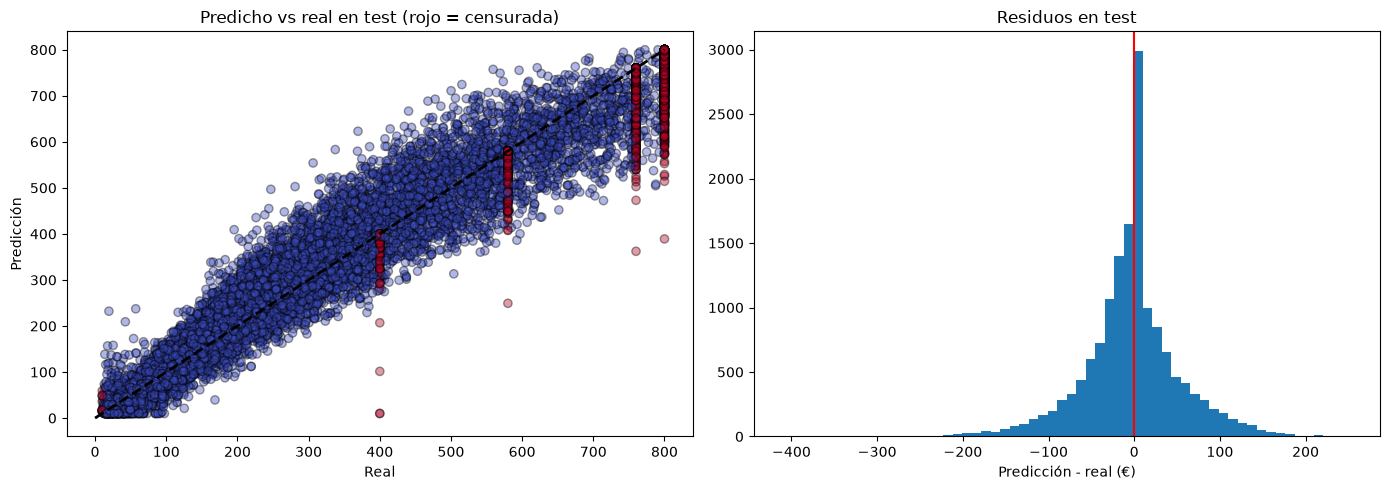

In [87]:
pred_sin_recortar = modelo_final.predict(preparar(final, test))
print("Predicciones sin recortar por debajo de 10 €:", (pred_sin_recortar < 10).sum())
print("Predicciones sin recortar por encima de su tope:", (pred_sin_recortar > test["Tope"]).sum())

pred_test = predecir(test)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test["Prima"], pred_test, c=test["Censurada"], cmap="coolwarm", edgecolors=(0, 0, 0), alpha=0.4)
axes[0].plot([0, 800], [0, 800], "k--", lw=2)
axes[0].set_title("Predicho vs real en test (rojo = censurada)")
axes[0].set_xlabel("Real")
axes[0].set_ylabel("Predicción")

axes[1].hist(pred_test - test["Prima"], bins=60)
axes[1].axvline(0, color="red")
axes[1].set_title("Residuos en test")
axes[1].set_xlabel("Predicción - real (€)")
plt.tight_layout()
plt.show()

| | Lineal | Final sin recortar | Final |
|---|---|---|---|
| RMSE | 141,8 € | 59,0 € | 56,7 € |
| MAE | 108,5 € | 42,4 € | 38,7 € |
| R² | 0,718 | 0,951 | 0,955 |

- Explica el 95,5 % de la variabilidad y se equivoca de media 38,7 €, casi tres veces menos que el lineal.
- Sin recortar habría 159 primas por debajo de 10 € y 1.727 por encima del tope. El recorte baja el RMSE de 59,0 € a 56,7 € y el MAE de 42,4 € a 38,7 € (en censurados, el RMSE de 64,1 € a 56,1 €).
- Error parecido en no censurados (56,9 €) y censurados (56,1 €).
- Test (56,7 €) y validación (57,6 €) casi iguales: el resultado no es optimista.

## 11. Interpretación del modelo final

Los coeficientes de un polinomio de grado 5 no se interpretan por separado. Dibujamos la curva de cada variable con las demás en su mediana, entre los percentiles 5 y 90 (fuera hay pocos datos). La duración, en sus 5 valores. Con la duración mediana (36 meses) el tope es 760 €.

In [88]:
mediana = train[variables].median()
mediana

Monto_Inicial           40000.00
Duracion                   36.00
Scoring_Crediticio        705.00
Ratio_Interes              10.58
Ratio_Deuda_Ingresos        0.29
Ingresos                39114.00
dtype: float64

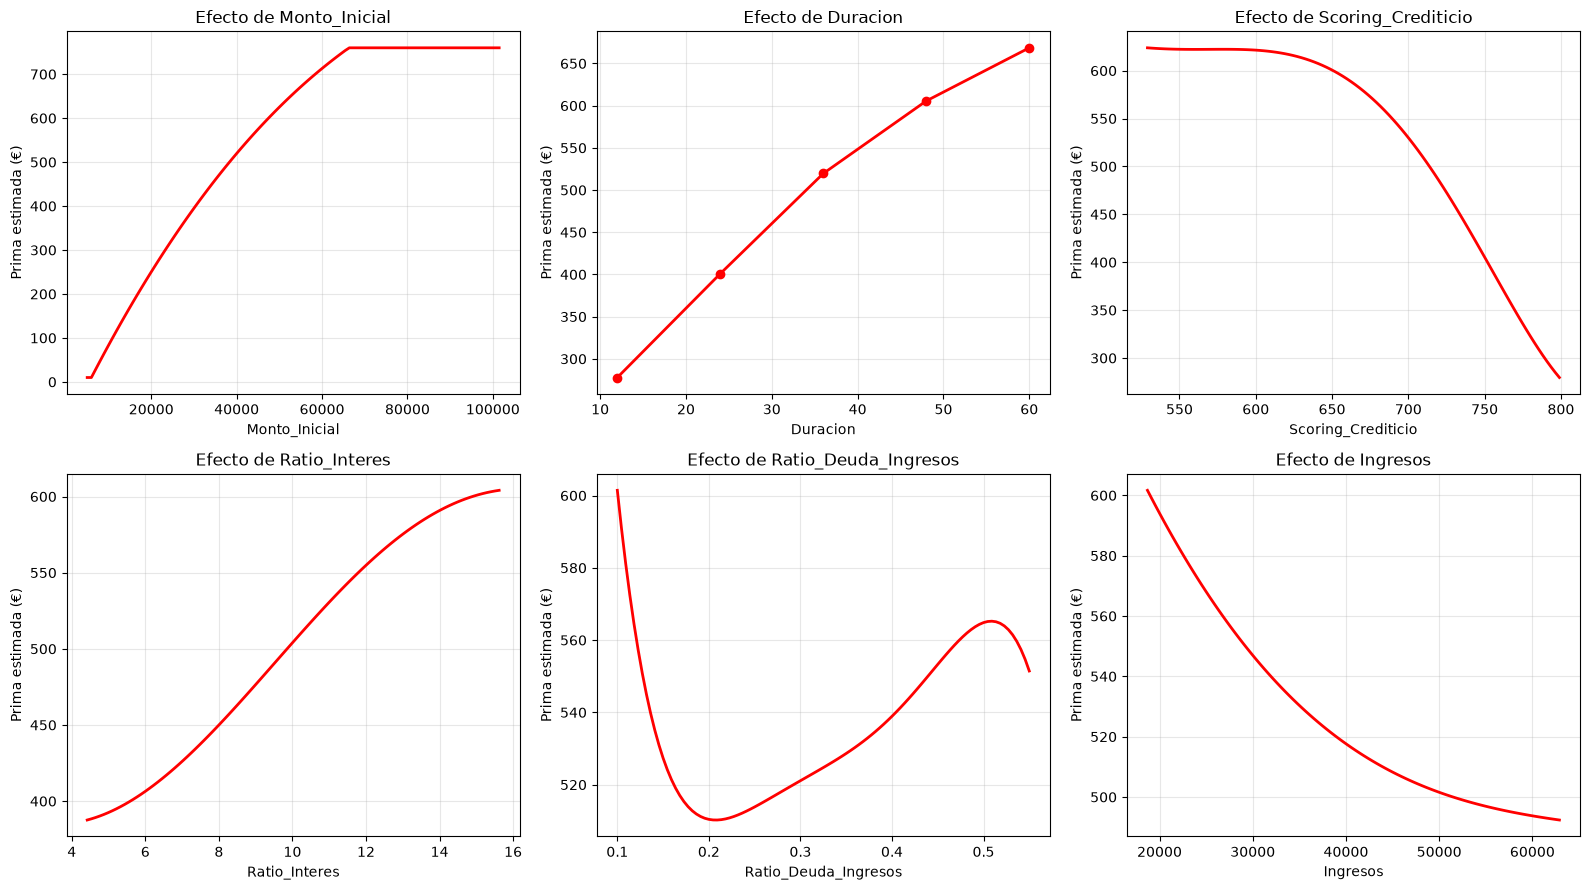

In [89]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, variable in zip(axes.flat, variables):
    if variable == "Duracion":
        valores = np.sort(train["Duracion"].unique())   # la duración solo toma 5 valores
    else:
        valores = np.linspace(train[variable].quantile(0.05), train[variable].quantile(0.90), 100)
    X_nuevo = pd.DataFrame({v: [mediana[v]] * len(valores) for v in variables})
    X_nuevo[variable] = valores
    ax.plot(valores, predecir(X_nuevo), "o-" if variable == "Duracion" else "-", color="red", linewidth=2)
    ax.set_xlabel(variable)
    ax.set_ylabel("Prima estimada (€)")
    ax.set_title(f"Efecto de {variable}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- Monto_Inicial: la que más influye. Sube cada vez más despacio hasta el tope (760 €) hacia los 66.000 €.
- Duracion: 278 € a 12 meses, 400 € a 24, 520 € a 36, 605 € a 48 y 668 € a 60.
- Scoring_Crediticio: casi no influye hasta unos 620 puntos; después baja hasta unos 280 € con 800.
- Ratio_Interes: de 388 € con un 4,4 % a 605 € con un 15,6 %.
- Ratio_Deuda_Ingresos: efecto pequeño (510-600 €).
- Ingresos: la prima baja de 602 € a 492 € entre 19.000 € y 63.000 €. En el lineal salía positivo, pero nos fiamos del polinomio, que predice mucho mejor.

Las curvas se tuercen en los extremos, algo típico de los polinomios de grado alto: no hay que darle significado.

### 11.1 Ejemplos con préstamos reales del test

In [90]:
ejemplos = test.sample(6, random_state=1)[variables + ["Prima"]].copy()
ejemplos.insert(0, "ID", ejemplos.index)

ejemplos["Prima_estimada"] = predecir(ejemplos).round(2)
ejemplos["Diferencia"] = (ejemplos["Prima_estimada"] - ejemplos["Prima"]).round(2)
ejemplos
ejemplos["Prima_estimada"] = predecir(ejemplos).round(2)
ejemplos["Diferencia"] = (ejemplos["Prima_estimada"] - ejemplos["Prima"]).round(2)
ejemplos

,ID,Monto_Inicial,Duracion,Scoring_Crediticio,Ratio_Interes,Ratio_Deuda_Ingresos,Ingresos,Prima,Prima_estimada,Diferencia
32126,32126,126152,48.0,639,9.02,0.55,50345.0,800.00,798.32,-1.68
64238,64238,35071,60.0,668,14.38,0.44,35372.0,800.00,753.38,-46.62
52149,52149,58357,48.0,754,8.37,0.55,36300.0,800.00,598.47,-201.53
51102,51102,28174,12.0,576,10.70,0.25,55809.0,144.14,231.38,87.24
67594,67594,32133,36.0,764,11.14,0.41,67909.0,206.82,267.44,60.62
18979,18979,11010,36.0,755,15.29,0.23,25460.0,94.04,91.75,-2.29


## 12. Prima estimada para todos los préstamos

In [91]:
datos.insert(0, "ID", datos.index)
datos["Prima_estimada"] = predecir(datos).round(2)
datos[["ID", "Prima", "Prima_estimada", "Probabilidad_Impago"]].to_csv("Prima_estimada.csv", index=False)
datos[["ID", "Prima", "Prima_estimada", "Probabilidad_Impago"]].head()

,ID,Prima,Prima_estimada,Probabilidad_Impago
0,0,580.00,573.99,0.031815
1,1,431.25,501.28,0.109607
2,2,760.00,714.60,0.127424
3,3,385.66,352.81,0.111428
4,4,535.14,621.96,0.033502


## 13. Conclusiones

- Datos censurados: tope de 400, 580, 760 y 800 € según la duración, y mínimo de 10 €. Afecta al 26,6 % de los préstamos. Las predicciones se recortan a esos límites.
- Escenario: A (todos los datos), elegido en validación. B mejora un poco los no censurados, pero falla mucho en los censurados (281 € frente a 56 €).
- Variables: Monto_Inicial, Duracion, Scoring_Crediticio, Ratio_Interes, Ratio_Deuda_Ingresos e Ingresos, por significancia, Lasso y parsimonia, comprobadas con el polinomio.
- p-valor: si es mayor que 0,05 no demuestra que una variable no influya, y con tantos datos casi todo es significativo; por eso decidimos con el error.
- Probabilidad de impago: no entra porque su información ya está casi toda en las variables del cliente (R² = 0,907). La prima sí depende del riesgo, a través del Scoring y del Ratio_Interes.

| Paso | Resultado |
|---|---|
| Lineal | R² = 0,68; no se cumplen normalidad ni homocedasticidad; relación no lineal. |
| Descenso de gradiente | Con buena tasa llega a la ecuación normal; el estocástico necesita bajar la tasa. |
| Polinomio | De 152 € a 59 € con grado 5. |
| Curvas de aprendizaje | Recta subajustada; grado 5 generaliza bien. |
| Regularización | Ninguna mejora de forma apreciable (casi no hay sobreajuste). SGD con la misma penalización queda por encima de Ridge exacto. |
| Hiperparámetros | Ridge con alpha = 0,1. |

Modelo final: polinomio de grado 5 con Ridge (alpha = 0,1), escenario A y predicciones recortadas.

| Test | R² | RMSE | MAE |
|---|---|---|---|
| Lineal | 0,718 | 141,8 € | 108,5 € |
| Final | 0,955 | 56,7 € | 38,7 € |

Para Lagun Aro: la prima depende sobre todo del importe y la duración del préstamo, y después de la calidad del cliente (mejor scoring y menor interés, menos prima).

Limitaciones: en los censurados el modelo aprende el límite, no la prima real; y solo es fiable dentro del rango de los datos.